# 2026 Senate Forecast — Ozempic (Swing)

The slimmed-down model ("Ozempic") built on Model 1 (`Models/Model_Full_Configs`). Same backbone — weighted polls, fundamentals, correlated simulations — but only a handful of team-tunable weights.

Fundamentals = **each state's 2024 presidential margin, shifted by how much the national mood has moved since 2024** (uniform swing). The other variant lives in the sibling folder; `Models/Model_Ozempic/README.md` explains the difference.

**What changed vs Model 1**
- **Polls come only from the VoteHub API** (no spreadsheet). Only polls from the last `WINDOW_DAYS` (28) count; weight falls linearly from 100% (today) to `WINDOW_OLDEST_WEIGHT` (25%) at day 28.
- **Kalshi** prediction-market odds are pulled live and enter each race at weight 1 (vs polls 10, fundamentals 5). They are also shown side-by-side with the model as a comparison.
- **Fixed blend** `polls : fundamentals : Kalshi = 10 : 5 : 1` instead of Model 1's Bayesian precision weighting.

**Outputs** (top of Step 7): **P(Democrats hold ≥ 51 seats)** and the **predicted number of Democratic seats** (incl. caucusing independents).

**How to use:** edit `CONFIG`, then *Run All*. Results go to `Output/` in this folder. API pulls are cached in `Models/Model_Ozempic/Data_Cache/`, so if VoteHub or Kalshi is down the last good pull is used.

All margins are **Democrat (or credible independent) minus Republican**, in points.

## Setup: install packages
Run once per computer (safe to re-run; packages you already have are skipped). Installs everything this notebook needs that doesn't ship with Python: `numpy`, `pandas`, `scipy`, `matplotlib`, and `jinja2` (formats the race table). Restart the kernel if anything was newly installed.

In [1]:
%pip install --quiet numpy pandas scipy matplotlib jinja2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy
import json
import re
import unicodedata
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

## CONFIG — the team's weights

These are the only knobs meant to be argued about. Everything else is in `SETTINGS` below and is fixed plumbing (file paths, the Senate map, constants carried over from Model 1).

In [3]:
CONFIG = {
    "AS_OF_DATE": None, # None = today. Set e.g. "2026-10-15" to backtest: only polls RELEASED by then count, and Kalshi
                        # prices are that day's close (pulled from Kalshi's price history), so nothing from after the date leaks in

    # ---- Final blend for each race: margin = weighted average of the three sources ----
    "W_POLLS": 10,
    "W_FUNDAMENTALS": 5,
    "W_KALSHI": 1, # 0 = Kalshi is comparison-only

    # ---- Rolling poll window ----
    "WINDOW_DAYS": 28, # polls older than this are dropped
    "WINDOW_OLDEST_WEIGHT": 0.25, # weight of a poll exactly WINDOW_DAYS old; falls linearly from 1.0 today

    # ---- Poll weights ----
    "POPULATION_WEIGHTS": {"LV": 1.0, "RV": 0.9, "A": 0.8}, # LV over RV, but not 2:1 (blackboard 100:90)
    "PARTISAN_SHIFT": 3.0, # pts moved AGAINST the sponsor of a partisan poll (R-sponsored -> D+3, D-sponsored -> R+3)
    # Pollsters VoteHub doesn't grade: "random" = in every simulation each one gets the grade + error of a randomly drawn
    # VoteHub-graded pollster (so missing grades add uncertainty instead of a fixed penalty); "fixed" = lowest rank (5), as before
    "UNRATED_POLLSTERS": "random",

    # ---- Fundamentals: Swing variant ----
    # fundamentals = 2024 state margin + (today's national environment - 2024 national margin) + incumbency
    # The two national signals are averaged with these weights to get "today's national environment".
    # The 2024 state margin is NOT weighted here: it is the baseline every state starts from (it always counts in full).
    "W_GENERIC_BALLOT": 2, # generic congressional ballot ("heavily")
    "W_APPROVAL": 1, # presidential approval ("general sentiment ... weighted less")

    # ---- Incumbency ----
    "INCUMBENCY_PTS": 3.0, # + toward the incumbent's party when the incumbent (elected or appointed) is on the ballot; open seats 0
}

## SETTINGS — plumbing and fixed constants

Not meant for tuning. The Senate map, incumbent status and the error/correlation constants are copied unchanged from Model 1 so the two models are comparable. The nominee and Kalshi tables were checked against VoteHub and Kalshi on 2026-10-26.

In [4]:
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").is_dir()) # first folder up with Data/
OZEMPIC_DIR = REPO_ROOT / "Models" / "Model_Ozempic"

SETTINGS = {
    "DATA_DIR": REPO_ROOT / "Data",
    "OUT_DIR": OZEMPIC_DIR / "Ozempic_Swing" / "Output",
    "CACHE_DIR": OZEMPIC_DIR / "Data_Cache", # shared by both Ozempic variants
    "PRES_2024_FILE": "pres_2024_results.csv", # Harris/Trump % by state (Wikipedia, certified results)
    "LEANS_FILE": "leans_and_regions.csv", # only Region + PartisanLean, for the between-state correlation
    "SCORECARD_FILE": "votehub_pollster_scorecards.csv", # VoteHub pollster grades + percent error
    "ELECTION_DAY": "2026-11-03",
    "N_SIMS": 10_000,
    "SEED": 2026,

    # ---- APIs ----
    "VOTEHUB_URL": "https://api.votehub.com/polls",
    "KALSHI_URL": "https://api.elections.kalshi.com/trade-api/v2",
    "KALSHI_CONTROL_MARKET": "CONTROLS-2026-D", # "Will Democrats win the U.S. Senate in 2026?"
    "USER_AGENT": "DACSS-Team5-forecast",

    # ---- Senate map (same as Model 1) ----
    "SEATS_UP": {
        "Alabama": "R", "Alaska": "R", "Arkansas": "R", "Florida": "R", "Idaho": "R",
        "Iowa": "R", "Kansas": "R", "Kentucky": "R", "Louisiana": "R", "Maine": "R",
        "Mississippi": "R", "Montana": "R", "Nebraska": "R", "North Carolina": "R",
        "Ohio": "R", "Oklahoma": "R", "South Carolina": "R", "South Dakota": "R",
        "Tennessee": "R", "Texas": "R", "West Virginia": "R", "Wyoming": "R",
        "Colorado": "D", "Delaware": "D", "Georgia": "D", "Illinois": "D",
        "Massachusetts": "D", "Michigan": "D", "Minnesota": "D", "New Hampshire": "D",
        "New Jersey": "D", "New Mexico": "D", "Oregon": "D", "Rhode Island": "D",
        "Virginia": "D",
    },
    "HOLDOVER_D": 34, "HOLDOVER_R": 31,
    "D_SEATS_FOR_CONTROL": 51, # R vice president breaks 50-50 ties
    "INDEPENDENT_CAUCUS_PROB_D": {"Nebraska": 0.8}, # P(Osborn caucuses with D if he wins), as in Model 1
    "INCUMBENT_STATUS": { # anything not listed = incumbent running (same as Model 1)
        "Illinois": "open", "Michigan": "open", "Minnesota": "open", "New Hampshire": "open",
        "Alabama": "open", "Iowa": "open", "Kentucky": "open", "Montana": "open",
        "North Carolina": "open", "Wyoming": "open", "Oklahoma": "open", "Texas": "open", "Louisiana": "open",
        "Florida": "appointed", "Ohio": "appointed", "South Carolina": "appointed",
    },

    # ---- Nominees: (opposition, Republican). Opposition None = take the highest-polling non-R candidate in each poll
    # (Sheet2 rule: a strong independent becomes the credible opposition). Polls missing either nominee
    # (old hypothetical match-ups, e.g. Pappas vs Scott Brown) are dropped. Names come from Kalshi's market list.
    "NOMINEES": {
        "Alabama": ("Everett Wess", "Barry Moore"), "Alaska": ("Mary Peltola", "Dan Sullivan"),
        "Arkansas": ("Hallie Shoffner", "Tom Cotton"), "Colorado": ("John Hickenlooper", "Mark Baisley"),
        "Delaware": ("Chris Coons", "Michael Katz"), "Florida": ("Angie Nixon", "Ashley Moody"),
        "Georgia": ("Jon Ossoff", "Mike Collins"), "Idaho": (None, "Jim Risch"),
        "Illinois": ("Juliana Stratton", "Don Tracy"), "Iowa": ("Josh Turek", "Ashley Hinson"),
        "Kansas": ("Adam Hamilton", "Roger Marshall"), "Kentucky": ("Charles Booker", "Andy Barr"),
        "Louisiana": ("Jamie Davis", "Julia Letlow"), "Maine": ("Troy Jackson", "Susan Collins"),
        "Massachusetts": ("Ed Markey", "John Deaton"), "Michigan": ("Abdul El-Sayed", "Mike Rogers"),
        "Minnesota": ("Peggy Flanagan", "Michele Tafoya"), "Mississippi": ("Scott Colom", "Cindy Hyde-Smith"),
        "Montana": (None, "Kurt Alme"), "Nebraska": ("Dan Osborn", "Pete Ricketts"),
        "New Hampshire": ("Chris Pappas", "John Sununu"), "New Jersey": ("Cory Booker", "Justin Murphy"),
        "New Mexico": ("Ben Ray Lujan", "Larry Marker"), "North Carolina": ("Roy Cooper", "Michael Whatley"),
        "Ohio": ("Sherrod Brown", "Jon Husted"), "Oklahoma": ("N'Kiyla Thomas", "Kevin Hern"),
        "Oregon": ("Jeff Merkley", "David Brock Smith"), "Rhode Island": ("Jack Reed", "Raymond McKay"),
        "South Carolina": ("Annie Andrews", "Darline Graham"), "South Dakota": (None, "Mike Rounds"),
        "Tennessee": ("Marquita Bradshaw", "Bill Hagerty"), "Texas": ("James Talarico", "Ken Paxton"),
        "Virginia": ("Mark Warner", "Bert Mizusawa"), "West Virginia": ("Rachel Fetty Anderson", "Shelley Moore Capito"),
        "Wyoming": ("James Byrd", "Harriet Hageman"),
    },

    # ---- Kalshi event per race. Mostly SENATE{ST}-26, but NOT always: Kalshi files Kentucky under SENATELA-26,
    # Louisiana under KXSENATELA-26NOV, and the FL/OH specials under SENATEFLS-26 / SENATEOHS-26.
    # The model reads the Republican ("-R") market and uses P(opposition) = 1 - P(R).
    "KALSHI_EVENTS": {
        "Alabama": "SENATEAL-26", "Alaska": "SENATEAK-26", "Arkansas": "SENATEAR-26", "Colorado": "SENATECO-26",
        "Delaware": "SENATEDE-26", "Florida": "SENATEFLS-26", "Georgia": "SENATEGA-26", "Idaho": "SENATEID-26",
        "Illinois": "SENATEIL-26", "Iowa": "SENATEIA-26", "Kansas": "SENATEKS-26", "Kentucky": "SENATELA-26",
        "Louisiana": "KXSENATELA-26NOV", "Maine": "SENATEME-26", "Massachusetts": "SENATEMA-26",
        "Michigan": "SENATEMI-26", "Minnesota": "SENATEMN-26", "Mississippi": "SENATEMS-26", "Montana": "SENATEMT-26",
        "Nebraska": "SENATENE-26", "New Hampshire": "SENATENH-26", "New Jersey": "SENATENJ-26",
        "New Mexico": "SENATENM-26", "North Carolina": "SENATENC-26", "Ohio": "SENATEOHS-26",
        "Oklahoma": "SENATEOK-26", "Oregon": "SENATEOR-26", "Rhode Island": "SENATERI-26",
        "South Carolina": "SENATESC-26", "South Dakota": "SENATESD-26", "Tennessee": "SENATETN-26",
        "Texas": "SENATETX-26", "Virginia": "SENATEVA-26", "West Virginia": "SENATEWV-26", "Wyoming": "SENATEWY-26",
    },
    "KALSHI_PROB_CLIP": (0.01, 0.99), # keep implied margins finite for 99%+ markets
    "KALSHI_HISTORY_START": "2026-06-01", # first day of daily price history pulled for backtests (AS_OF_DATE)

    # ---- National signals (generic ballot, approval) ----
    # VoteHub has few national polls in any 4-week stretch, so if the window holds fewer than NAT_MIN_POLLS,
    # the N most recent are used instead (older ones get WINDOW_OLDEST_WEIGHT).
    "NAT_MIN_POLLS": 5,
    "GB_POPULATION_PREFERENCE": ["LV", "RV", "A"], # one survey released for several populations -> keep the most voter-like
    "ENV_SLOPE": 0.35, # pts of margin per pt of net approval (Model 1 default)
    "NAT_2024_MARGIN": -1.48, # Harris - Trump national popular vote, 2024 (overwritten from the data file below)

    # ---- Poll handling (Model 1 defaults) ----
    "OTHER_TO_UNDECIDED_H2H": 1.0, # head-to-head: everything not D/R is undecided
    "OTHER_TO_UNDECIDED_FULL_FIELD": 0.5, # full field: half of "other" is real third-party support
    "REFERENCE_SAMPLE": 800, "SAMPLE_SIZE_CAP": 2500, "MISSING_SAMPLE_SIZE": 600,
    "GRADE_TO_RANK": {"A+": 10, "A": 9, "B": 8, "C": 7, "D": 6, "F": 5}, # VoteHub grade -> Model 1's 5-10 scale
    "UNRATED_RANK": 5, "MIN_QUALITY_WEIGHT": 0.5, # rank 5 counts half as much as rank 10
    "ACCURACY_WEIGHT_CLIP": (0.5, 2.0), # w_accuracy = (median error / pollster error)^2, clipped
    "SINGLE_POLL_SD": 5.0, # Model 1: 1.25 x 4-pt typical error
    "SYSTEMATIC_POLL_ERROR_SD": 4.5, "UNDECIDED_SPLIT_SD": 0.15,
    "FUNDAMENTALS_SD": 7.5, # Model 1's PRIOR_SD
    "INDEPENDENT_SD_MULT": 1.3,

    # ---- Simulation (Model 1 defaults) ----
    "DAILY_DRIFT_SD": 0.25, "T_DF": 5,
    "CORR_NATIONAL": 0.45, "CORR_REGION": 0.15, "CORR_LEAN": 0.15, "LEAN_SCALE": 10,
    "RATING_TOSSUP": 0.60, "RATING_LEAN": 0.75, "RATING_LIKELY": 0.95,

    # ---- Sensitivity sweep over CONFIG keys ----
    "RUN_SWEEP": True, "SWEEP_N_SIMS": 3000,
    "SWEEP_PARAMS": {
        "W_POLLS": [5, 10, 20],
        "W_FUNDAMENTALS": [0, 2.5, 5, 10],
        "W_KALSHI": [0, 1, 3, 5],
        "WINDOW_DAYS": [14, 21, 28, 42],
        "WINDOW_OLDEST_WEIGHT": [0.0, 0.25, 0.5, 1.0],
        "POPULATION_WEIGHTS": [{"LV": 1.0, "RV": r, "A": r - 0.1} for r in (0.5, 0.75, 0.9, 1.0)],
        "PARTISAN_SHIFT": [0, 1.5, 3, 5],
        "UNRATED_POLLSTERS": ["fixed", "random"],
        "W_GENERIC_BALLOT": [0, 1, 2, 4],
        "W_APPROVAL": [0, 1, 2],
        "INCUMBENCY_PTS": [0, 1.5, 3, 5],
    },
}
S = SETTINGS


def validate(cfg, S):
    assert min(cfg["W_POLLS"], cfg["W_FUNDAMENTALS"], cfg["W_KALSHI"]) >= 0 and cfg["W_POLLS"] + cfg["W_FUNDAMENTALS"] > 0
    assert 0 <= cfg["WINDOW_OLDEST_WEIGHT"] <= 1 and cfg["WINDOW_DAYS"] > 0
    assert S["HOLDOVER_D"] + S["HOLDOVER_R"] + len(S["SEATS_UP"]) == 100
    assert set(S["NOMINEES"]) == set(S["SEATS_UP"]) == set(S["KALSHI_EVENTS"]), "every race needs nominees and a Kalshi event"
    assert cfg["UNRATED_POLLSTERS"] in ("random", "fixed")
    bad = set(S["SWEEP_PARAMS"]) - set(cfg)
    assert not bad, f"SWEEP_PARAMS has keys that are not in CONFIG: {bad}"


validate(CONFIG, S)
S["OUT_DIR"].mkdir(parents=True, exist_ok=True)
S["CACHE_DIR"].mkdir(parents=True, exist_ok=True)
print(f"repo root: {REPO_ROOT} | outputs -> {S['OUT_DIR']}")

repo root: /mnt/attach/outputs/repo | outputs -> /mnt/attach/outputs/repo/Models/Model_Ozempic/Ozempic_Swing/Output


### Shared settings from `run_all.py`
When `run_all.py` runs every model for a comparison, it makes them all use the same date (today's system date) and the same number of simulations (10,000). It does this through two environment variables, which this cell reads. **When you run this notebook yourself, nothing is set and your CONFIG/SETTINGS values are used.**

In [5]:
import os
if os.environ.get("FORECAST_AS_OF"): # set only by run_all.py
    CONFIG["AS_OF_DATE"] = os.environ["FORECAST_AS_OF"]
if os.environ.get("FORECAST_N_SIMS"):
    S["N_SIMS"] = int(os.environ["FORECAST_N_SIMS"])
if os.environ.get("FORECAST_AS_OF") or os.environ.get("FORECAST_N_SIMS"):
    print(f"run_all.py overrides: AS_OF_DATE = {CONFIG['AS_OF_DATE']}, N_SIMS = {S['N_SIMS']:,}")

run_all.py overrides: AS_OF_DATE = 2026-10-26, N_SIMS = 10,000


## Step 1: Pull the data

| Source | What | Fallback if the API fails |
|---|---|---|
| VoteHub `poll_type=us-senator` | State Senate polls | `Data_Cache/votehub_senate_cache.csv` |
| VoteHub `poll_type=generic-ballot` | Generic congressional ballot | `Data_Cache/votehub_generic_ballot_cache.csv` |
| VoteHub `poll_type=approval`, subject Donald Trump | Presidential approval | `Data_Cache/votehub_approval_cache.csv` |
| Kalshi events API | P(Republican wins) per race + P(D control), today | `Data_Cache/kalshi_cache.csv` |
| Kalshi candlesticks API (only when `AS_OF_DATE` is set) | Daily closing prices of the same markets since `KALSHI_HISTORY_START` | `Data_Cache/kalshi_history_cache.csv` |
| `Data/pres_2024_results.csv` | 2024 presidential result by state | — |
| `Data/votehub_pollster_scorecards.csv` | VoteHub pollster grades and error | — |

Each successful pull overwrites its cache, so the cache is always the last good copy.

In [6]:
def http_json(url, timeout=20):
    req = urllib.request.Request(url, headers={"User-Agent": S["USER_AGENT"], "Accept": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.load(r)


SOURCE_STATUS = {} # name -> "live" or "cache (...)"; saved in the standard export for run_all.py


def with_cache(name, fetch, parse_dates):
    """Run fetch(); save to the cache on success, read the cache on failure."""
    path = S["CACHE_DIR"] / name
    try:
        df = fetch()
        df.to_csv(path, index=False)
        SOURCE_STATUS[name] = "live"
        print(f"{name}: fetched {len(df)} rows live")
    except Exception as e:  # network down, API changed, ...
        if not path.exists():
            raise RuntimeError(f"{name}: API failed ({type(e).__name__}: {e}) and there is no cache") from e
        df = pd.read_csv(path)
        SOURCE_STATUS[name] = f"cache ({type(e).__name__})"
        print(f"{name}: API unavailable ({type(e).__name__}); using cache with {len(df)} rows")
    for c in parse_dates:
        if c in df.columns: # older caches may lack newer columns (e.g. created_at)
            df[c] = pd.to_datetime(df[c])
    return df


def fetch_senate():
    rows = []
    for p in http_json(f"{S['VOTEHUB_URL']}?poll_type=us-senator"):
        subj = str(p.get("subject") or "")
        if not subj.startswith("2026 ") or subj.endswith((" Democratic", " Republican")):
            continue # keep 2026 general-election polls only (drop primaries)
        state = subj[5:]
        if state not in S["SEATS_UP"]:
            continue
        rows.append({"id": p.get("id"), "end_date": p.get("end_date"), "created_at": p.get("created_at"),
                     "state": state, "pollster": p.get("pollster"),
                     "sample_size": p.get("sample_size"), "population": (p.get("population") or "").lower(),
                     "partisan": p.get("partisan") or "", "internal": bool(p.get("internal")),
                     "answers": "|".join(f"{a['choice']}={a['pct']}" for a in p.get("answers", []))})
    return pd.DataFrame(rows)


def fetch_national(poll_type, keys, extra=""):
    rows = []
    for p in http_json(f"{S['VOTEHUB_URL']}?poll_type={poll_type}{extra}"):
        ans = {a["choice"].strip().lower(): a["pct"] for a in p.get("answers", [])}
        vals = [next((v for k, v in ans.items() if k.startswith(key)), None) for key in keys]
        if None in vals:
            continue
        rows.append({"Date": p.get("end_date"), "Released": p.get("created_at"), "Pollster": p.get("pollster"),
                     **dict(zip(COLS[poll_type], vals)),
                     "SampleSize": p.get("sample_size"), "Population": (p.get("population") or "").upper(),
                     "Partisan": bool(p.get("partisan") or p.get("internal"))})
    return pd.DataFrame(rows)


COLS = {"generic-ballot": ["Dem", "Rep"], "approval": ["Approve", "Disapprove"]}


def kalshi_mid(m):
    """Mid price of a Kalshi market in [0, 1]; handles the *_dollars (new) and cents (old) field styles."""
    def f(k):
        v = m.get(k + "_dollars", None)
        if v not in (None, ""):
            return float(v)
        v = m.get(k)
        return None if v in (None, "") else float(v) / 100
    bid, ask, last = f("yes_bid"), f("yes_ask"), f("last_price")
    if bid and ask and ask >= bid:
        return (bid + ask) / 2
    return last


def fetch_kalshi():
    rows = []
    for state, ev in S["KALSHI_EVENTS"].items():
        j = http_json(f"{S['KALSHI_URL']}/events/{ev}?with_nested_markets=true")
        markets = j.get("markets") or j.get("event", {}).get("markets", [])
        rep = next(m for m in markets if m["ticker"].endswith("-R"))
        p_rep = kalshi_mid(rep)
        rows.append({"State": state, "event_ticker": ev, "market_ticker": rep["ticker"], "p_rep": p_rep,
                     "p_opp": 1 - p_rep, "fetched": pd.Timestamp.today().strftime("%Y-%m-%d")})
    ctrl = http_json(f"{S['KALSHI_URL']}/markets/{S['KALSHI_CONTROL_MARKET']}")["market"]
    rows.append({"State": "CONTROL", "event_ticker": ctrl.get("event_ticker"), "market_ticker": ctrl["ticker"],
                 "p_rep": np.nan, "p_opp": kalshi_mid(ctrl), "fetched": pd.Timestamp.today().strftime("%Y-%m-%d")})
    return pd.DataFrame(rows)


def candle_value(c, side):
    """Closing price (0-1) from one Kalshi candlestick; handles *_dollars (new) and cents (old) fields."""
    d = c.get(side) or {}
    if d.get("close_dollars") not in (None, ""):
        return float(d["close_dollars"])
    return None if d.get("close") in (None, "") else float(d["close"]) / 100


def fetch_kalshi_history():
    """Daily closes of every race's Republican market and the control market (one API call per market)."""
    start = int(pd.Timestamp(S["KALSHI_HISTORY_START"], tz="UTC").timestamp())
    end = int(pd.Timestamp.now(tz="UTC").timestamp())
    rows = []
    for m in [f"{ev}-R" for ev in S["KALSHI_EVENTS"].values()] + [S["KALSHI_CONTROL_MARKET"]]:
        series = m.split("-")[0] # e.g. SENATEME-26-R -> SENATEME
        j = http_json(f"{S['KALSHI_URL']}/series/{series}/markets/{m}/candlesticks"
                      f"?start_ts={start}&end_ts={end}&period_interval=1440")
        for c in j.get("candlesticks", []):
            rows.append({"market_ticker": m, "end_period_ts": c["end_period_ts"], "yes_bid": candle_value(c, "yes_bid"),
                         "yes_ask": candle_value(c, "yes_ask"), "last": candle_value(c, "price")})
    return pd.DataFrame(rows)


def kalshi_as_of(data, today):
    """Kalshi table (State, p_opp) as of `today`: the live snapshot for today, else each market's last daily close
    on or before that date (NaN if the market had not traded yet -> Kalshi just drops out of that race)."""
    if today >= pd.Timestamp.today().normalize():
        return data["kalshi"]
    if "kalshi_history" not in data:
        data["kalshi_history"] = with_cache("kalshi_history_cache.csv", fetch_kalshi_history, [])
    h = data["kalshi_history"]
    cutoff = (today + pd.Timedelta(days=1)).tz_localize("America/New_York").timestamp() # end of that day, Eastern
    h = h[h["end_period_ts"] <= cutoff].sort_values("end_period_ts").groupby("market_ticker").last()
    bid, ask, last = (pd.to_numeric(h[c], errors="coerce") for c in ("yes_bid", "yes_ask", "last"))
    price = pd.Series(np.where(bid.notna() & ask.notna() & (bid > 0) & (ask >= bid), (bid + ask) / 2, last), index=h.index)
    rows = [{"State": st, "p_rep": price.get(f"{ev}-R", np.nan), "p_opp": 1 - price.get(f"{ev}-R", np.nan)}
            for st, ev in S["KALSHI_EVENTS"].items()]
    rows.append({"State": "CONTROL", "p_rep": np.nan, "p_opp": price.get(S["KALSHI_CONTROL_MARKET"], np.nan)})
    return pd.DataFrame(rows)


def load_static():
    d = S["DATA_DIR"]
    pres = pd.read_csv(d / S["PRES_2024_FILE"]).set_index("State")
    pres["margin2024"] = pres["Harris_pct"] - pres["Trump_pct"] # D - R
    S["NAT_2024_MARGIN"] = float(pres.loc["National", "margin2024"])
    leans = pd.read_csv(d / S["LEANS_FILE"], encoding="utf-8-sig")
    leans = leans[leans["State"] != "Source"].assign(State=lambda x: x["State"].str.strip())
    leans["PartisanLean"] = pd.to_numeric(leans["PartisanLean"])
    cards = pd.read_csv(d / S["SCORECARD_FILE"])
    return {"pres": pres, "leans": leans.set_index("State"), "scorecards": cards}


DATA = {
    **load_static(),
    "senate": with_cache("votehub_senate_cache.csv", fetch_senate, ["end_date", "created_at"]),
    "generic": with_cache("votehub_generic_ballot_cache.csv", lambda: fetch_national("generic-ballot", ["dem", "rep"]),
                          ["Date", "Released"]),
    "approval": with_cache("votehub_approval_cache.csv",
                           lambda: fetch_national("approval", ["approve", "disapprove"], "&subject=Donald%20Trump"),
                           ["Date", "Released"]),
    "kalshi": with_cache("kalshi_cache.csv", fetch_kalshi, []),
}

votehub_senate_cache.csv: API unavailable (URLError); using cache with 95 rows


votehub_generic_ballot_cache.csv: API unavailable (URLError); using cache with 548 rows


votehub_approval_cache.csv: API unavailable (URLError); using cache with 9 rows


kalshi_cache.csv: API unavailable (URLError); using cache with 36 rows


## Step 2: State polls → one polling average per race

1. **Match candidates.** VoteHub lists candidates by name, not party, so each poll's answers are matched to the nominees in `SETTINGS["NOMINEES"]` by surname. Polls that don't include both nominees (old hypothetical match-ups) are dropped.
2. **Margin.** `other = 100 − opp − R`; part of it is undecided and breaks like decided voters (Model 1's "proportional" rule).
3. **Rolling window.** Only polls that ended in the last `WINDOW_DAYS` count. Weight = `1 − (1 − WINDOW_OLDEST_WEIGHT) × age / WINDOW_DAYS`, i.e. 100% today → 25% at day 28.
4. **Other weights** (multiplied): sample size (√n, capped), population (LV / RV / A), VoteHub pollster grade, VoteHub accuracy, and survey versions (an LV + RV release of the same survey splits one weight). **Ungraded pollsters** (about half the polls) get, in every simulation, the grade and error of a randomly drawn VoteHub-graded pollster (`UNRATED_POLLSTERS = "random"`), so missing grades widen the uncertainty instead of applying a fixed penalty; tables show their average weight. **Every poll counts on its own** — no "flooding" penalty — so a state polled by one or two firms still gets full use of them.
5. **Partisan sponsor:** margin shifted `PARTISAN_SHIFT` pts against the sponsor.

In [7]:
def surname(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"[^a-z\- ]", "", s).strip()
    return s.split()[-1] if s else ""


def parse_answers(s):
    out = []
    for part in str(s).split("|"):
        if "=" in part:
            name, pct = part.rsplit("=", 1)
            out.append((name.strip(), float(pct)))
    return out


def match_poll(row):
    """Return (opp_pct, rep_pct, n_candidates) or None if this poll doesn't have both nominees."""
    opp_name, rep_name = S["NOMINEES"][row["state"]]
    ans = parse_answers(row["answers"])
    rep = next((p for n, p in ans if surname(n) == surname(rep_name)), None)
    if rep is None:
        return None
    others = [(n, p) for n, p in ans if surname(n) != surname(rep_name)]
    if opp_name:
        opp = next((p for n, p in others if surname(n) == surname(opp_name)), None)
    else:
        opp = max((p for _, p in others), default=None) # top non-Republican = credible opposition
    return None if opp is None else (opp, rep, len(ans))


def build_scorecard_lookup(cards):
    key = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
    lut = {}
    for _, r in cards.iterrows():
        names = [r["Scorecard_Name"]] + ([a for a in str(r["Aliases"]).split("|")] if pd.notna(r["Aliases"]) else [])
        for n in names:
            lut[key(n)] = (S["GRADE_TO_RANK"].get(r["Grade"], S["UNRATED_RANK"]), float(r["Percent_Error"]))
    return lambda pollster: lut.get(key(pollster), (S["UNRATED_RANK"], np.nan))


def card_weights(cards):
    """quality x accuracy weight of every VoteHub-graded pollster (the pool unrated pollsters are drawn from)."""
    rank = cards["Grade"].map(S["GRADE_TO_RANK"]).fillna(S["UNRATED_RANK"]).to_numpy(dtype=float)
    q = S["MIN_QUALITY_WEIGHT"] + (1 - S["MIN_QUALITY_WEIGHT"]) * (np.clip(rank, 5, 10) - 5) / 5
    a = np.clip((cards["Percent_Error"].median() / cards["Percent_Error"].to_numpy()) ** 2, *S["ACCURACY_WEIGHT_CLIP"])
    return q, q * a


POLL_COLS = ["state", "pollster", "end_date", "age", "opp_pct", "rep_pct", "n_cands", "undecided", "margin", "undecided_sd",
             "partisan_shift", "adj_margin", "unrated", "w_base", "w_quality", "w_accuracy", "weight", "family"]


def prepare_polls(data, cfg, today, verbose=False):
    raw = data["senate"].copy()
    raw = raw[raw["state"].isin(S["SEATS_UP"])]
    if "created_at" in raw.columns: # backtests: only polls already PUBLISHED by `today`
        raw = raw[raw["created_at"].isna() | (raw["created_at"] <= today)]
    age = (today - raw["end_date"]).dt.days
    p = raw[(age >= 0) & (age <= cfg["WINDOW_DAYS"])].copy() # rolling window (and as-of filter)
    p["age"] = (today - p["end_date"]).dt.days
    n_window = len(p)
    matched = p.apply(match_poll, axis=1) if n_window else pd.Series(dtype=object)
    keep = matched.notna().to_numpy(dtype=bool) if n_window else np.zeros(0, dtype=bool)
    p, matched = p[keep].copy(), matched[keep]
    if verbose:
        print(f"State polls: {len(raw)} general-election polls -> {n_window} in the last {cfg['WINDOW_DAYS']} days "
              f"-> {len(p)} with both nominees")
    if p.empty: # e.g. AS_OF_DATE before any polls: every race runs on fundamentals + Kalshi
        return pd.DataFrame(columns=POLL_COLS)
    p["opp_pct"] = [m[0] for m in matched]
    p["rep_pct"] = [m[1] for m in matched]
    p["n_cands"] = [m[2] for m in matched]
    # margin with undecideds allocated proportionally
    o, r = p["opp_pct"], p["rep_pct"]
    other = (100 - o - r).clip(lower=0)
    frac = np.where(p["n_cands"] > 2, S["OTHER_TO_UNDECIDED_FULL_FIELD"], S["OTHER_TO_UNDECIDED_H2H"])
    u = other * frac
    p["undecided"] = u
    p["margin"] = (o - r) * (o + r + u) / (o + r)
    p["undecided_sd"] = 2 * u * S["UNDECIDED_SPLIT_SD"]
    # partisan sponsor shift (VoteHub: partisan = "REP" / "DEM")
    party = p["partisan"].fillna("").astype(str).str.upper()
    p["partisan_shift"] = np.where(party.str.startswith("REP"), cfg["PARTISAN_SHIFT"],
                                   np.where(party.str.startswith("DEM"), -cfg["PARTISAN_SHIFT"], 0.0))
    p["adj_margin"] = p["margin"] + p["partisan_shift"]
    # weights
    p["w_recency"] = 1 - (1 - cfg["WINDOW_OLDEST_WEIGHT"]) * p["age"] / cfg["WINDOW_DAYS"]
    n = pd.to_numeric(p["sample_size"], errors="coerce").fillna(S["MISSING_SAMPLE_SIZE"]).clip(upper=S["SAMPLE_SIZE_CAP"])
    p["w_size"] = np.sqrt(n / S["REFERENCE_SAMPLE"])
    pop = p["population"].fillna("").astype(str).str.upper().replace({"ADULTS": "A", "V": "RV"})
    p["w_population"] = pop.map(cfg["POPULATION_WEIGHTS"]).fillna(1.0)
    lookup = build_scorecard_lookup(data["scorecards"])
    rank_err = p["pollster"].map(lookup)
    p["pollster_rank"] = [x[0] for x in rank_err]
    p["pollster_error"] = [x[1] for x in rank_err]
    p["unrated"] = p["pollster_error"].isna()
    lo, hi = 5, 10
    p["w_quality"] = S["MIN_QUALITY_WEIGHT"] + (1 - S["MIN_QUALITY_WEIGHT"]) * (p["pollster_rank"].clip(lo, hi) - lo) / (hi - lo)
    med_err = data["scorecards"]["Percent_Error"].median()
    p["w_accuracy"] = ((med_err / p["pollster_error"]) ** 2).fillna(1.0).clip(*S["ACCURACY_WEIGHT_CLIP"])
    if cfg["UNRATED_POLLSTERS"] == "random": # tables use the AVERAGE over the graded pool; simulations redraw (Step 6)
        q_card, qa_card = card_weights(data["scorecards"])
        p.loc[p["unrated"], "w_quality"] = q_card.mean()
        p.loc[p["unrated"], "w_accuracy"] = qa_card.mean() / q_card.mean()
    p["family"] = p["end_date"].dt.strftime("%Y-%m-%d") + " | " + p["state"] + " | " + p["pollster"]
    p["w_version"] = 1.0 / p.groupby("family")["family"].transform("size")
    wcols = [c for c in p.columns if c.startswith("w_")]
    p["w_base"] = p[[c for c in wcols if c not in ("w_quality", "w_accuracy")]].prod(axis=1) # everything except the grade
    p["weight"] = p["w_base"] * p["w_quality"] * p["w_accuracy"]
    return p.reset_index(drop=True)


def polling_averages(p):
    rows = {}
    for st, g in p.groupby("state"):
        w = g["weight"].to_numpy()
        n_eff = w.sum() ** 2 / (w ** 2).sum()
        und_sd = np.average(g["undecided_sd"], weights=w)
        sd = np.sqrt(S["SINGLE_POLL_SD"] ** 2 / n_eff + S["SYSTEMATIC_POLL_ERROR_SD"] ** 2 + und_sd ** 2)
        rows[st] = {"poll_mean": np.average(g["adj_margin"], weights=w), "poll_sd": sd,
                    "n_polls": len(g), "n_eff": n_eff}
    return pd.DataFrame.from_dict(rows, orient="index", columns=["poll_mean", "poll_sd", "n_polls", "n_eff"]).astype(float)

## Step 3: National signals

- **Generic ballot**: weighted two-party margin `100 × (D − R) / (D + R)` of VoteHub generic-ballot polls in the window (same LV/RV/A and recency weights as state polls; a survey released for several populations keeps only its most voter-like version).
- **Approval**: weighted net approval, converted to a margin with `ENV_SLOPE × −net` (an unpopular Republican president helps Democrats).

VoteHub carries few national polls, so if fewer than `NAT_MIN_POLLS` fall in the window the most recent `NAT_MIN_POLLS` are used and anything older than the window gets the oldest-window weight.

In [8]:
def national_average(df, value_fn, cfg, today):
    if df is None or df.empty:
        return np.nan, 0
    g = df[df["Date"] <= today].copy()
    if "Released" in g.columns: # backtests: only polls already published by `today`
        g = g[g["Released"].isna() | (g["Released"] <= today)]
    g["Population"] = g["Population"].fillna("").astype(str).str.upper().replace({"ADULTS": "A"})
    rank = {pop: i for i, pop in enumerate(S["GB_POPULATION_PREFERENCE"])}
    g["pop_rank"] = g["Population"].map(rank).fillna(len(rank))
    g = g.sort_values("pop_rank").drop_duplicates(["Date", "Pollster"], keep="first")
    age = (today - g["Date"]).dt.days
    use = g[age <= cfg["WINDOW_DAYS"]]
    if len(use) < S["NAT_MIN_POLLS"]:
        use = g.nlargest(S["NAT_MIN_POLLS"], "Date")
    if use.empty:
        return np.nan, 0
    a = (today - use["Date"]).dt.days.clip(lower=0, upper=cfg["WINDOW_DAYS"])
    w = 1 - (1 - cfg["WINDOW_OLDEST_WEIGHT"]) * a / cfg["WINDOW_DAYS"]
    n = pd.to_numeric(use["SampleSize"], errors="coerce").fillna(1000).replace(0, 1000).clip(upper=S["SAMPLE_SIZE_CAP"])
    w = w * np.sqrt(n / 1000) * use["Population"].map(cfg["POPULATION_WEIGHTS"]).fillna(1.0)
    w = w * np.where(use["Partisan"].astype(str).str.lower().isin(["true", "1"]), 0.6, 1.0)
    return float(np.average(value_fn(use), weights=w)), len(use)


def national_signals(data, cfg, today):
    gb, n_gb = national_average(data["generic"], lambda d: 100 * (d["Dem"] - d["Rep"]) / (d["Dem"] + d["Rep"]), cfg, today)
    net, n_ap = national_average(data["approval"], lambda d: d["Approve"] - d["Disapprove"], cfg, today)
    appr = S["ENV_SLOPE"] * -net if not np.isnan(net) else np.nan # R president: negative net approval helps D
    return {"gb": gb, "n_gb": n_gb, "net_approval": net, "appr": appr, "n_appr": n_ap}

## Step 4: Fundamentals (Swing)

$$\text{fund}_s = \text{margin2024}_s + \underbrace{\left(\frac{w_{GB}\cdot GB + w_{AP}\cdot AP}{w_{GB}+w_{AP}} - \text{margin2024}_{US}\right)}_{\text{national swing since 2024}} \pm \text{incumbency}$$

- `margin2024_s` = Harris − Trump in the state (e.g. Alabama −30.5, Maine +6.9).
- `margin2024_US` = Harris − Trump nationally = −1.5.
- `GB` = generic-ballot margin (D − R, two-party basis); `AP` = approval converted to a margin (`ENV_SLOPE × −net approval`).
- Every state moves by the same national swing, so a deep-red state stays deep red and a swing state moves into whichever column the national environment favors.

In [9]:
def fundamentals(races, env, cfg, S):
    """Swing: 2024 state margin + national swing since 2024 + incumbency."""
    w_gb, w_ap = cfg["W_GENERIC_BALLOT"], cfg["W_APPROVAL"]
    parts = [(w_gb, env["gb"]), (w_ap, env["appr"])]
    parts = [(w, v) for w, v in parts if w > 0 and v is not None and not np.isnan(v)]  # skip missing signals
    nat_now = sum(w * v for w, v in parts) / sum(w for w, _ in parts) if parts else S["NAT_2024_MARGIN"]
    swing = nat_now - S["NAT_2024_MARGIN"] # how far the country has moved since 2024 (+ = toward D)
    out = races["margin2024"] + swing + races["incumbency_pts"]
    return out, {"national_now": nat_now, "swing_since_2024": swing}


## Step 5: Kalshi

Kalshi gives a probability, not a margin. To put it on the same scale as the polls and fundamentals, it is converted to the margin that would produce that probability **under this model's own uncertainty** for the race:

$$\text{kalshi\_margin}_s = \Phi^{-1}(P_{\text{Kalshi}}) \times \sigma_s$$

where σ is the race's SD from polls + fundamentals. So if Kalshi says 75% and the race SD is 5 pts, Kalshi "votes" for a D+3.4 margin. Probabilities are clipped to 1–99%.

In [10]:
def kalshi_margins(ktable, sd):
    k = ktable.set_index("State")
    p = k["p_opp"].reindex(sd.index).astype(float).clip(*S["KALSHI_PROB_CLIP"])
    return norm.ppf(p) * sd, k["p_opp"].reindex(sd.index)

## Step 6: Blend and simulate

Each race's margin is the weighted average of the sources it has:

$$\text{margin}_s = \frac{W_P\cdot\text{polls}_s + W_F\cdot\text{fund}_s + W_K\cdot\text{kalshi}_s}{W_P + W_F + W_K}$$

A race with no polls in the window uses fundamentals and Kalshi only (weights renormalized). The race SD treats the sources' errors as independent, `σ = √Σ (wᵢ/W)² σᵢ²`, plus drift for the days left. The simulation is Model 1's: correlated Student-t errors (shared national + region + similar-lean), 10,000 elections, Osborn caucusing with Democrats 80% of the time.

In [11]:
def build_races(data, cfg, today, verbose=False):
    races = pd.DataFrame(index=sorted(S["SEATS_UP"]))
    races.index.name = "State"
    races["incumbent_party"] = pd.Series(S["SEATS_UP"])
    races["status"] = pd.Series(S["INCUMBENT_STATUS"]).reindex(races.index).fillna("running")
    races["independent"] = races.index.isin(list(S["INDEPENDENT_CAUCUS_PROB_D"]))
    races = races.join(data["pres"][["margin2024"]]).join(data["leans"][["PartisanLean", "Region"]])
    inc = np.where(races["status"] == "open", 0.0, cfg["INCUMBENCY_PTS"])
    races["incumbency_pts"] = np.where(races["incumbent_party"] == "D", inc, -inc)
    env = national_signals(data, cfg, today)
    races["fund_mean"], fund_info = fundamentals(races, env, cfg, S)
    races["fund_sd"] = S["FUNDAMENTALS_SD"] * np.where(races["independent"], S["INDEPENDENT_SD_MULT"], 1.0)
    polls = prepare_polls(data, cfg, today, verbose)
    races = races.join(polls_avg := polling_averages(polls))
    races["n_polls"] = races["n_polls"].fillna(0).astype(int)
    days_left = max((pd.Timestamp(S["ELECTION_DAY"]) - today).days, 0)
    drift = S["DAILY_DRIFT_SD"] * np.sqrt(days_left)

    # polls + fundamentals first (this SD is also the scale for Kalshi's implied margin)
    wp = np.where(races["poll_mean"].notna(), cfg["W_POLLS"], 0.0)
    wf = np.where(wp + cfg["W_FUNDAMENTALS"] > 0, float(cfg["W_FUNDAMENTALS"]), 1.0) # no polls and W_FUNDAMENTALS=0 -> fall back to fundamentals
    W = wp + wf
    races["pf_mean"] = (wp * races["poll_mean"].fillna(0) + wf * races["fund_mean"]) / W
    races["pf_sd"] = np.sqrt((wp / W) ** 2 * races["poll_sd"].fillna(0) ** 2 + (wf / W) ** 2 * races["fund_sd"] ** 2 + drift ** 2)
    ktable = kalshi_as_of(data, today) # today's prices, or that day's close when backtesting
    races["kalshi_margin"], races["kalshi_p"] = kalshi_margins(ktable, races["pf_sd"])

    wk = np.where(races["kalshi_margin"].notna(), cfg["W_KALSHI"], 0.0)
    W = wp + wf + wk
    races["post_mean"] = (wp * races["poll_mean"].fillna(0) + wf * races["fund_mean"] + wk * races["kalshi_margin"].fillna(0)) / W
    races["post_sd"] = np.sqrt((wp / W) ** 2 * races["poll_sd"].fillna(0) ** 2 + (wf / W) ** 2 * races["fund_sd"] ** 2
                               + (wk / W) ** 2 * races["pf_sd"] ** 2 + drift ** 2)
    races["share_polls"], races["share_fund"], races["share_kalshi"] = wp / W, wf / W, wk / W
    return races, polls, env, fund_info, ktable


def correlation_matrix(races):
    lean = races["PartisanLean"].to_numpy(dtype=float)
    region = races["Region"].to_numpy(dtype=object)
    R = (S["CORR_NATIONAL"] + S["CORR_REGION"] * (region[:, None] == region[None, :])
         + S["CORR_LEAN"] * np.exp(-np.abs(lean[:, None] - lean[None, :]) / S["LEAN_SCALE"]))
    np.fill_diagonal(R, 1.0)
    return R


def poll_mean_draws(polls, races, data, cfg, n_sims, rng):
    """Race means for each simulation when ungraded pollsters get a random VoteHub grade in every simulation.
    Returns an (n_sims x races) array, or None if there is nothing to randomize."""
    unr = polls["unrated"].to_numpy(dtype=bool) if len(polls) else np.zeros(0, dtype=bool)
    if cfg["UNRATED_POLLSTERS"] != "random" or not unr.any():
        return None
    _, qa_card = card_weights(data["scorecards"])
    codes, uniq = pd.factorize(polls.loc[unr, "pollster"]) # one draw per POLLSTER per simulation (its polls share it)
    draw = rng.integers(0, len(qa_card), size=(n_sims, len(uniq)))
    W = np.tile(polls["weight"].to_numpy(dtype=float), (n_sims, 1))
    W[:, unr] = polls.loc[unr, "w_base"].to_numpy(dtype=float) * qa_card[draw][:, codes]
    states = races.index.to_numpy()
    ind = (polls["state"].to_numpy()[:, None] == states[None, :]).astype(float) # polls x races
    den = W @ ind
    with np.errstate(invalid="ignore", divide="ignore"):
        pm = (W * polls["adj_margin"].to_numpy(dtype=float)) @ ind / den # per-sim polling average (NaN = no polls)
    shift = races["share_polls"].to_numpy() * (pm - races["poll_mean"].to_numpy()) # move each race by its poll share
    return races["post_mean"].to_numpy() + np.nan_to_num(shift)


def simulate(races, n_sims, rng, means=None):
    k = len(races)
    L = np.linalg.cholesky(correlation_matrix(races))
    z = rng.standard_normal((n_sims, k)) @ L.T
    df = S["T_DF"]
    z = z / np.sqrt(rng.chisquare(df, size=(n_sims, 1)) / df) * np.sqrt((df - 2) / df) # shared fat tail, variance 1
    base = races["post_mean"].to_numpy() if means is None else means # per-simulation means when grades are redrawn
    margins = base + races["post_sd"].to_numpy() * z
    wins = margins > 0
    caucus = np.ones_like(wins)
    for st, prob in S["INDEPENDENT_CAUCUS_PROB_D"].items():
        caucus[:, races.index.get_loc(st)] = rng.random(n_sims) < prob
    d_seats = S["HOLDOVER_D"] + (wins & caucus).sum(axis=1)
    return wins.mean(axis=0), d_seats, pd.DataFrame(margins, columns=races.index)


def run_model(data, cfg, n_sims=None, verbose=True):
    validate(cfg, S)
    today = pd.Timestamp(cfg["AS_OF_DATE"]) if cfg["AS_OF_DATE"] else pd.Timestamp.today().normalize()
    rng = np.random.default_rng(S["SEED"])
    races, polls, env, fund_info, ktable = build_races(data, cfg, today, verbose)
    n_sims = n_sims or S["N_SIMS"]
    means = poll_mean_draws(polls, races, data, cfg, n_sims, rng)
    races["p_dem"], d_seats, sims = simulate(races, n_sims, rng, means)
    need = S["D_SEATS_FOR_CONTROL"]
    summary = {"p_d_51": float((d_seats >= need).mean()), "exp_d_seats": float(d_seats.mean()),
               "median_d_seats": float(np.median(d_seats)), "p10": float(np.percentile(d_seats, 10)),
               "p90": float(np.percentile(d_seats, 90))}
    if verbose:
        f = lambda x: "n/a" if x is None or np.isnan(x) else f"{x:+.1f}"
        print(f"As of {today:%Y-%m-%d}: generic ballot D{f(env['gb'])} ({env['n_gb']} polls), "
              f"net approval {f(env['net_approval'])} -> approval margin D{f(env['appr'])} ({env['n_appr']} polls)")
        print("Fundamentals: " + ", ".join(f"{k} = {v:.0%}" if k.startswith("share") else f"{k} = {v:+.2f}"
                                           for k, v in fund_info.items()))
        if means is not None:
            u = polls[polls["unrated"]]
            print(f"Ungraded pollsters: {u['pollster'].nunique()} ({len(u)} of {len(polls)} polls) get a random VoteHub grade "
                  f"in each of the {n_sims:,} simulations")
    return {"races": races, "polls": polls, "env": env, "fund_info": fund_info, "d_seats": d_seats,
            "sims": sims, "summary": summary, "today": today, "kalshi": ktable}


RES = run_model(DATA, CONFIG)
RES_NO_KALSHI = run_model(DATA, {**CONFIG, "W_KALSHI": 0}, verbose=False) # same model with Kalshi switched off

State polls: 95 general-election polls -> 89 in the last 28 days -> 89 with both nominees
As of 2026-10-26: generic ballot D+9.0 (5 polls), net approval -22.3 -> approval margin D+7.8 (5 polls)
Fundamentals: national_now = +8.62, swing_since_2024 = +10.10
Ungraded pollsters: 31 (49 of 89 polls) get a random VoteHub grade in each of the 10,000 simulations


## Step 7: Results

### The two headline numbers

In [12]:
s, s0 = RES["summary"], RES_NO_KALSHI["summary"]
kal = RES["kalshi"].set_index("State") # as of the run date (history when backtesting)
k_ctrl = float(kal.loc["CONTROL", "p_opp"]) if "CONTROL" in kal.index else np.nan
k_seats = S["HOLDOVER_D"] + sum(kal.loc[st, "p_opp"] * S["INDEPENDENT_CAUCUS_PROB_D"].get(st, 1.0) for st in S["SEATS_UP"])
print(f"P(Democrats hold at least 51 seats): {s['p_d_51']:.1%}")
print(f"Predicted Democratic seats (mean):   {s['exp_d_seats']:.1f}   (median {s['median_d_seats']:.0f}, 80% range {s['p10']:.0f}-{s['p90']:.0f})")
print()
print(f"Same model, Kalshi weight 0:         P(51+) {s0['p_d_51']:.1%}, mean seats {s0['exp_d_seats']:.1f}")
print(f"Kalshi alone:                        P(D control) {k_ctrl:.1%} (CONTROLS-2026-D), expected seats {k_seats:.1f} (sum of race odds)")

P(Democrats hold at least 51 seats): 58.5%
Predicted Democratic seats (mean):   51.2   (median 51, 80% range 48-55)

Same model, Kalshi weight 0:         P(51+) 57.6%, mean seats 51.2
Kalshi alone:                        P(D control) 63.5% (CONTROLS-2026-D), expected seats 51.7 (sum of race odds)


### Race by race
`share_*` columns show how much of each race's margin came from polls, fundamentals and Kalshi.

In [13]:
def margin_label(m):
    return f"D+{m:.1f}" if m >= 0 else f"R+{-m:.1f}"


def rating(p, st):
    opp = "Ind" if st in S["INDEPENDENT_CAUCUS_PROB_D"] else "D"
    fav, top = (opp, p) if p >= 0.5 else ("R", 1 - p)
    if top < S["RATING_TOSSUP"]:
        return "Toss-up"
    return ("Lean" if top < S["RATING_LEAN"] else "Likely" if top < S["RATING_LIKELY"] else "Safe") + f" {fav}"


r = RES["races"]
race_table = pd.DataFrame({
    "inc": r["incumbent_party"] + " / " + r["status"], "2024": r["margin2024"].map(margin_label),
    "n_polls": r["n_polls"], "polls": r["poll_mean"].map(lambda x: margin_label(x) if pd.notna(x) else "-"),
    "fund": r["fund_mean"].map(margin_label), "kalshi_margin": r["kalshi_margin"].map(margin_label),
    "share_polls": r["share_polls"], "share_fund": r["share_fund"], "share_kalshi": r["share_kalshi"],
    "final": r["post_mean"].map(margin_label), "sd": r["post_sd"],
    "P(D/Ind win)": r["p_dem"], "Kalshi P": r["kalshi_p"], "model - Kalshi": r["p_dem"] - r["kalshi_p"],
})
race_table["rating"] = [rating(p, st) for st, p in r["p_dem"].items()]
race_table = race_table.sort_values("P(D/Ind win)", ascending=False)
race_table.style.format({c: "{:.0%}" for c in ["share_polls", "share_fund", "share_kalshi", "P(D/Ind win)", "Kalshi P", "model - Kalshi"]} | {"sd": "{:.1f}"})

,inc,2024,n_polls,polls,fund,kalshi_margin,share_polls,share_fund,share_kalshi,final,sd,P(D/Ind win),Kalshi P,model - Kalshi,rating
State,,,,,,,,,,,,,,,
Massachusetts,D / running,D+25.2,2,D+29.3,D+38.3,D+9.9,62%,31%,6%,D+30.9,4.5,100%,98%,2%,Safe D
Rhode Island,D / running,D+13.8,1,D+24.7,D+26.9,D+11.6,62%,31%,6%,D+24.6,5.0,100%,98%,1%,Safe D
Oregon,D / running,D+14.3,0,-,D+27.4,D+15.4,0%,83%,17%,D+25.4,6.4,100%,98%,2%,Safe D
Delaware,D / running,D+14.7,0,-,D+27.8,D+15.2,0%,83%,17%,D+25.7,6.4,100%,98%,2%,Safe D
Colorado,D / running,D+11.0,0,-,D+24.1,D+15.3,0%,83%,17%,D+22.6,6.4,100%,98%,2%,Safe D
Illinois,D / open,D+10.9,2,D+15.5,D+21.0,D+9.8,62%,31%,6%,D+16.9,4.5,100%,98%,2%,Safe D
New Mexico,D / running,D+6.0,1,D+20.0,D+19.1,D+10.5,62%,31%,6%,D+19.1,5.2,100%,97%,3%,Safe D
New Jersey,D / running,D+5.9,0,-,D+19.0,D+14.5,0%,83%,17%,D+18.3,6.4,99%,97%,2%,Safe D
Virginia,D / running,D+5.8,0,-,D+18.9,D+15.4,0%,83%,17%,D+18.3,6.4,99%,98%,1%,Safe D


### Model vs Kalshi
Points off the diagonal are races where the model and the market disagree. Above the line = the model is more bullish on Democrats than Kalshi.

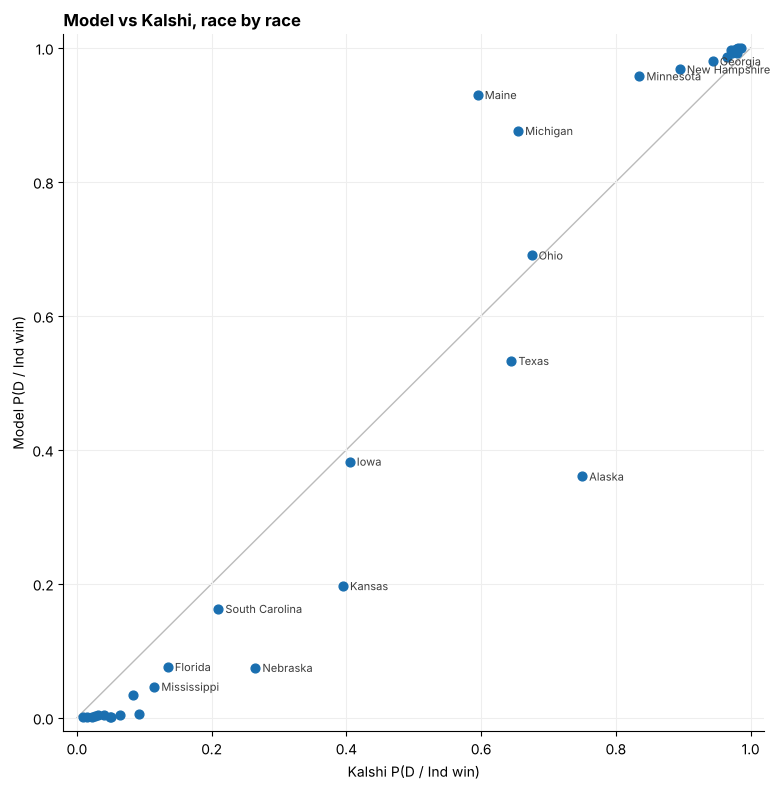

In [14]:
def plot_vs_kalshi(r, path=None):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.plot([0, 1], [0, 1], color="#BBBBBB", lw=1, zorder=1)
    ax.scatter(r["kalshi_p"], r["p_dem"], s=40, color="#1A6FB0", zorder=3)
    for st, row in r.iterrows():
        if 0.1 < row["kalshi_p"] < 0.95 or abs(row["p_dem"] - row["kalshi_p"]) > 0.1: # label only races worth discussing
            ax.annotate(st, (row["kalshi_p"], row["p_dem"]), xytext=(5, -3), textcoords="offset points", fontsize=8, color="#3C3C3C")
    ax.set_xlabel("Kalshi P(D / Ind win)")
    ax.set_ylabel("Model P(D / Ind win)")
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.grid(color="#EEEEEE", zorder=0)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_title("Model vs Kalshi, race by race", loc="left", fontweight="bold")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


plot_vs_kalshi(RES["races"], S["OUT_DIR"] / "model_vs_kalshi.png")

### Seat distribution

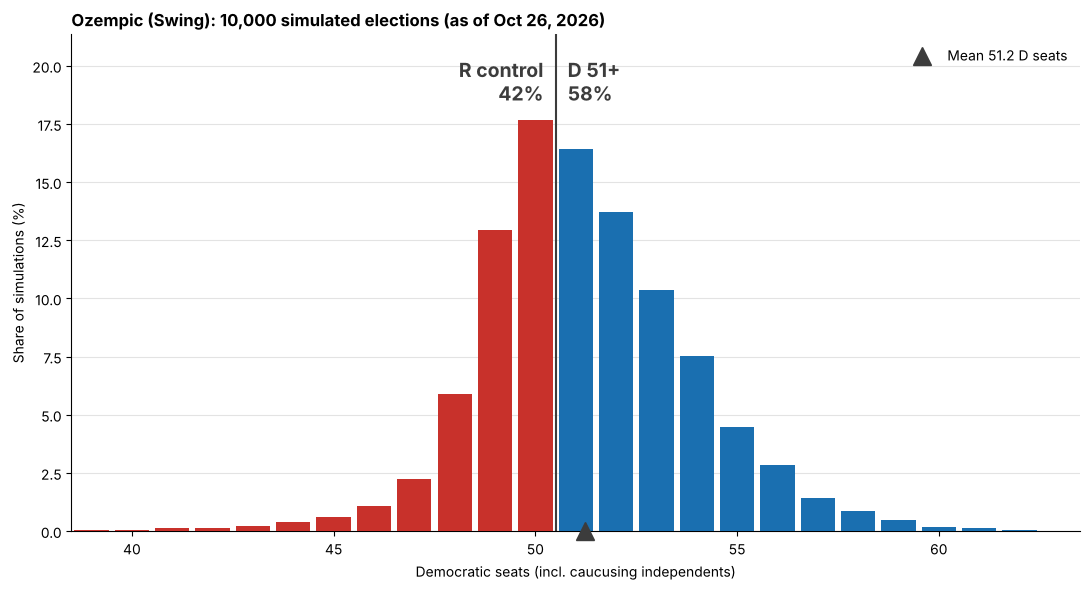

In [15]:
def plot_seat_distribution(d_seats, today, path=None):
    DEM_BLUE, REP_RED, INK = "#1A6FB0", "#C8312B", "#3C3C3C"
    need = S["D_SEATS_FOR_CONTROL"]
    seats, counts = np.unique(d_seats, return_counts=True)
    pct = 100 * counts / len(d_seats)
    p_dem = (d_seats >= need).mean()
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.bar(seats, pct, width=0.85, color=np.where(seats >= need, DEM_BLUE, REP_RED), zorder=3)
    ax.axvline(need - 0.5, color=INK, lw=1.5, zorder=2)
    ax.plot([d_seats.mean()], [0], marker="^", ms=13, color=INK, clip_on=False, zorder=5, ls="none",
            label=f"Mean {d_seats.mean():.1f} D seats") # marker on the axis so it never hides the control line
    top = pct.max() * 1.15
    ax.text(need - 0.8, top, f"R control\n{1 - p_dem:.0%}", ha="right", va="top", color=INK, fontsize=14, fontweight="bold")
    ax.text(need - 0.2, top, f"D 51+\n{p_dem:.0%}", ha="left", va="top", color=INK, fontsize=14, fontweight="bold")
    ax.set_ylim(0, top * 1.05)
    ax.set_xlim(np.percentile(d_seats, 0.1) - 1.5, np.percentile(d_seats, 99.9) + 1.5)
    ax.set_xlabel("Democratic seats (incl. caucusing independents)")
    ax.set_ylabel("Share of simulations (%)")
    ax.grid(axis="y", color="#E3E3E3", zorder=0)
    ax.spines[["right", "top"]].set_visible(False)
    ax.legend(loc="upper right", frameon=False)
    ax.set_title(f"Ozempic (Swing): {len(d_seats):,} simulated elections (as of {today:%b %d, %Y})", loc="left", fontweight="bold")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


plot_seat_distribution(RES["d_seats"], RES["today"], S["OUT_DIR"] / "seat_distribution.png")

### Save outputs

In [16]:
out = S["OUT_DIR"]
race_table.to_csv(out / "race_table.csv")
RES["polls"].to_csv(out / "polls_used.csv", index=False)
pd.Series(RES["d_seats"]).value_counts().sort_index().rename("n_sims").to_csv(out / "seat_distribution.csv", index_label="dem_seats")
headline = {"as_of": f"{RES['today']:%Y-%m-%d}", "variant": "Swing", **RES["summary"],
            "no_kalshi": RES_NO_KALSHI["summary"], "kalshi_p_control": k_ctrl, "kalshi_expected_seats": k_seats,
            "env": RES["env"], "fundamentals": RES["fund_info"], "config": CONFIG}
with open(out / "headline.json", "w") as f:
    json.dump(headline, f, indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x))
print(f"Saved race_table.csv, polls_used.csv, seat_distribution.csv/.png, model_vs_kalshi.png, headline.json to {out}")

Saved race_table.csv, polls_used.csv, seat_distribution.csv/.png, model_vs_kalshi.png, headline.json to /mnt/attach/outputs/repo/Models/Model_Ozempic/Ozempic_Swing/Output


### Standard export for `run_all.py`
Every model in the repo writes the same three files to `Output/standard/` so `run_all.py` can compare them without knowing how each model works: `summary.json` (headline numbers + key settings), `races.csv` (one row per race) and `seats.csv` (seat distribution). See the repo README.

In [17]:
STD = S["OUT_DIR"] / "standard"
STD.mkdir(parents=True, exist_ok=True)
_r = RES["races"]
pd.DataFrame({"state": _r.index, "p_dem": _r["p_dem"].values, "margin": _r["post_mean"].values, "sd": _r["post_sd"].values,
              "kalshi_p": _r["kalshi_p"].values, "n_polls": _r["n_polls"].values}).to_csv(STD / "races.csv", index=False)
_sh = pd.Series(RES["d_seats"]).value_counts(normalize=True).sort_index()
pd.DataFrame({"dem_seats": _sh.index, "share": _sh.values}).to_csv(STD / "seats.csv", index=False)
_c = CONFIG
_fund = (f"Literal (2024 {_c['W_STATE_2024']} : generic ballot {_c['W_GENERIC_BALLOT']} : approval {_c['W_APPROVAL']})"
         if "W_STATE_2024" in _c else f"Swing (generic ballot {_c['W_GENERIC_BALLOT']} : approval {_c['W_APPROVAL']})")
STANDARD = {
    "model": "Ozempic", "variant": headline["variant"], "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "as_of": f"{RES['today']:%Y-%m-%d}", **RES["summary"], "n_sims": int(S["N_SIMS"]),
    "kalshi_p_control": k_ctrl, "kalshi_expected_seats": k_seats, "sources": SOURCE_STATUS,
    "key_settings": {
        "Poll source": "VoteHub API",
        "Poll age": f"last {_c['WINDOW_DAYS']} days, weight 1.0 -> {_c['WINDOW_OLDEST_WEIGHT']}",
        "Polls : fundamentals : Kalshi": f"{_c['W_POLLS']} : {_c['W_FUNDAMENTALS']} : {_c['W_KALSHI']} (fixed)",
        "Poll reliability (thin races)": "none",
        "Fundamentals": _fund,
        "Incumbency": f"{_c['INCUMBENCY_PTS']:g} pts",
        "LV : RV : A": " : ".join(f"{v:g}" for v in _c["POPULATION_WEIGHTS"].values()),
        "Flooding penalty": "none",
        "House effects": "none",
        "Ungraded pollsters": _c["UNRATED_POLLSTERS"],
        "National signals": "VoteHub polls",
        "Kalshi races": "input + comparison (hand-coded tickers)",
        "Source errors": "independent",
    },
}
with open(STD / "summary.json", "w") as f:
    json.dump(STANDARD, f, indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x))
print(f"Standard export -> {STD}")

Standard export -> /mnt/attach/outputs/repo/Models/Model_Ozempic/Ozempic_Swing/Output/standard


## Step 8: Sensitivity sweep

Changes **one CONFIG weight at a time** (others stay at their CONFIG values) and re-runs with `SWEEP_N_SIMS` simulations and the same seed. The tornado shows which weights move P(D ≥ 51) the most.

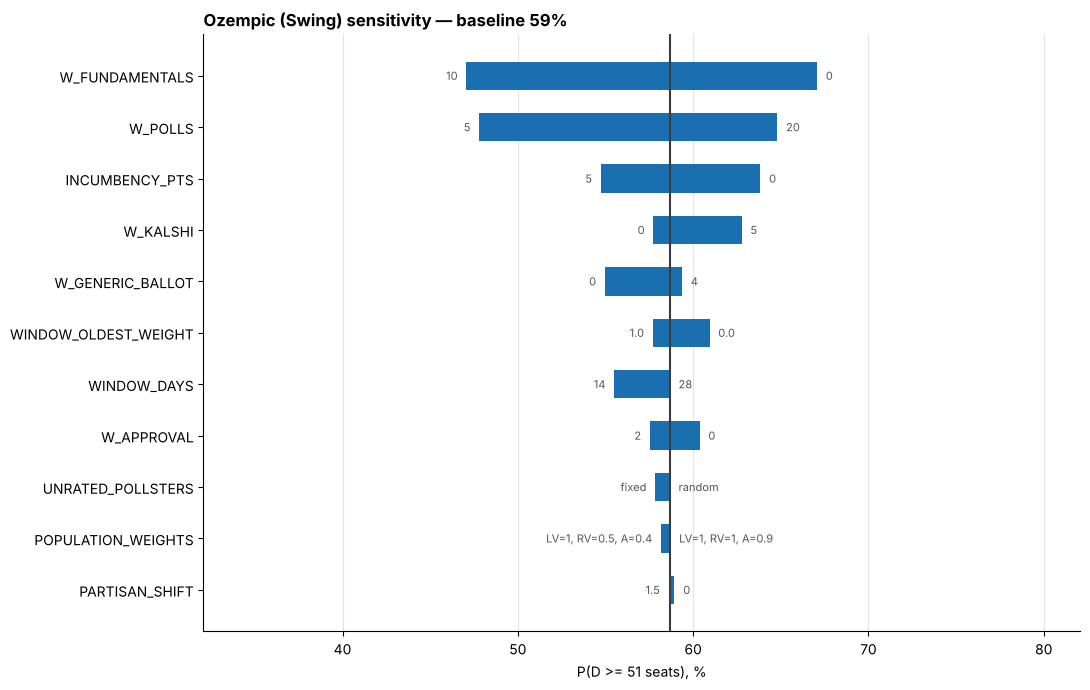

,param,value,is_default,p_d_51,exp_d_seats
0,W_POLLS,5,False,0.478,50.814
1,W_POLLS,10,True,0.587,51.282
2,W_POLLS,20,False,0.648,51.685
3,W_FUNDAMENTALS,0,False,0.671,52.092
4,W_FUNDAMENTALS,2.5,False,0.656,51.686
5,W_FUNDAMENTALS,5,True,0.587,51.282
6,W_FUNDAMENTALS,10,False,0.471,50.799
7,W_KALSHI,0,False,0.577,51.276
8,W_KALSHI,1,True,0.587,51.282
9,W_KALSHI,3,False,0.605,51.320


In [18]:
def value_label(v):
    if isinstance(v, dict):
        return ", ".join(f"{k}={x:g}" for k, x in v.items())
    return str(v)


def run_sweep(data, cfg):
    base = run_model(data, cfg, n_sims=S["SWEEP_N_SIMS"], verbose=False)["summary"]
    rows = []
    for key, values in S["SWEEP_PARAMS"].items():
        for v in values:
            c = copy.deepcopy(cfg)
            c[key] = v
            res = run_model(data, c, n_sims=S["SWEEP_N_SIMS"], verbose=False)["summary"]
            rows.append({"param": key, "value": value_label(v), "is_default": v == cfg[key],
                         "p_d_51": res["p_d_51"], "exp_d_seats": res["exp_d_seats"]})
    return pd.DataFrame(rows), base


def plot_tornado(sweep, base, path=None):
    rng_ = sweep.groupby("param")["p_d_51"].agg(["min", "max"])
    lo_lab = sweep.loc[sweep.groupby("param")["p_d_51"].idxmin()].set_index("param")["value"]
    hi_lab = sweep.loc[sweep.groupby("param")["p_d_51"].idxmax()].set_index("param")["value"]
    rng_ = rng_.assign(span=rng_["max"] - rng_["min"]).sort_values("span")
    fig, ax = plt.subplots(figsize=(11, 0.5 * len(rng_) + 1.5))
    y = np.arange(len(rng_))
    ax.barh(y, 100 * rng_["span"], left=100 * rng_["min"], height=0.55, color="#1A6FB0", zorder=3)
    ax.axvline(100 * base["p_d_51"], color="#3C3C3C", lw=1.5, zorder=4)
    for i, (param, rr) in enumerate(rng_.iterrows()):
        ax.text(100 * rr["min"] - 0.5, i, lo_lab[param], ha="right", va="center", fontsize=8, color="#555555")
        ax.text(100 * rr["max"] + 0.5, i, hi_lab[param], ha="left", va="center", fontsize=8, color="#555555")
    ax.set_yticks(y, rng_.index)
    ax.set_xlabel("P(D >= 51 seats), %")
    ax.grid(axis="x", color="#E3E3E3", zorder=0)
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_title(f"Ozempic (Swing) sensitivity — baseline {base['p_d_51']:.0%}", loc="left", fontweight="bold")
    ax.set_xlim(max(0, 100 * rng_["min"].min() - 15), min(100, 100 * rng_["max"].max() + 15))
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


if S["RUN_SWEEP"]:
    sweep, sweep_base = run_sweep(DATA, CONFIG)
    sweep.to_csv(S["OUT_DIR"] / "sensitivity_sweep.csv", index=False)
    plot_tornado(sweep, sweep_base, S["OUT_DIR"] / "sensitivity_tornado.png")
    display(sweep.round(3))